### 03 — EndoVis Full-Video Tracking & Kinematics (Dataset 1)

**Purpose:** Run **inference, not training**, on all 1,107 Dataset 1 frames using an existing YOLO Pose checkpoint. Save raw detections, associate two instrument identities over time, and calculate unsmoothed image-plane kinematics.

**Important:** Only 210 frames have manual annotations; results on other frames are predictions, not independently validated ground truth. Tracking is heuristic and may swap identities during crossing/occlusion. Speeds are **pixels/second**, not physical instrument speeds. Original frames and labels are never modified.

### 1. Imports and project paths
Run from the repository root (or from a `notebooks/` subdirectory). Requires `ultralytics`, `opencv-python`, `numpy`, `pandas`, `scipy`, and `matplotlib`.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from scipy.optimize import linear_sum_assignment
from ultralytics import YOLO

ROOT = Path.cwd().resolve()
if not (ROOT / 'EndoVisPoseAnnotation').is_dir() and (ROOT.parent / 'EndoVisPoseAnnotation').is_dir():
    ROOT = ROOT.parent
SOURCE = ROOT / 'EndoVisPoseAnnotation'
DATASET1 = SOURCE / 'Tracking_Robotic_Training' / 'Training' / 'Dataset1'
FRAMES = DATASET1 / 'EndoVis_Frames_set1' / 'Dataset1'
TIMESTAMPS = FRAMES / 'timestamps.csv'
OUTPUT = ROOT / 'runs' / 'endovis_tracking' / 'dataset1_baseline'
OUTPUT.mkdir(parents=True, exist_ok=True)
assert FRAMES.is_dir() and TIMESTAMPS.is_file(), 'Check Dataset 1 frame/timestamp paths'
print('Frames:', FRAMES)
print('Output:', OUTPUT)

Frames: C:\Users\default.LAPTOP-914PEJ5D\Documents\CV\Computer-Vison-Course-project\EndoVisPoseAnnotation\Tracking_Robotic_Training\Training\Dataset1\EndoVis_Frames_set1\Dataset1
Output: C:\Users\default.LAPTOP-914PEJ5D\Documents\CV\Computer-Vison-Course-project\runs\endovis_tracking\dataset1_baseline


## 2. Select checkpoint and inference settings
Change `SELECTED_RUN` to evaluate a different run. No training is performed.

In [2]:
SELECTED_RUN = 'yolo11n_dataset1_baseline-2'
CHECKPOINT_NAME = 'best.pt'
WEIGHTS = ROOT / 'runs' / 'endovis_pose' / SELECTED_RUN / 'weights' / CHECKPOINT_NAME
assert WEIGHTS.is_file(), f'Checkpoint not found: {WEIGHTS}'
MODEL = YOLO(str(WEIGHTS))
CONF = 0.25
IMGSZ = 640
DEVICE = 'cpu'  # Set to 0 if PyTorch/CUDA is available
MAX_ASSOCIATION_DISTANCE_PX = 100.0  # Tune after inspecting tracks
MAX_MISSING_FRAMES = 10
print('Using:', WEIGHTS)

Using: C:\Users\default.LAPTOP-914PEJ5D\Documents\CV\Computer-Vison-Course-project\runs\endovis_pose\yolo11n_dataset1_baseline-2\weights\best.pt


### 3. Load and verify the frame timeline
Use recorded timestamps, not an assumed fixed frame interval. Check missing/duplicate filenames and timestamp monotonicity.

In [3]:
timeline = pd.read_csv(TIMESTAMPS).sort_values('frame_id').reset_index(drop=True)
required = {'frame_id','filename','timestamp_seconds'}
assert required.issubset(timeline.columns), f'Missing timestamp columns: {required - set(timeline.columns)}'
assert timeline['filename'].is_unique and timeline['frame_id'].is_unique
assert timeline['timestamp_seconds'].is_monotonic_increasing
assert not timeline['timestamp_seconds'].duplicated().any()
missing = [name for name in timeline['filename'] if not (FRAMES / name).is_file()]
assert not missing, f'Missing frame images, e.g. {missing[:5]}'
print(f'Frames: {len(timeline)}, time range: {timeline.timestamp_seconds.iloc[0]:.2f}–{timeline.timestamp_seconds.iloc[-1]:.2f} s')
display(timeline.head())

Frames: 1107, time range: 0.00–44.24 s


,frame_id,filename,timestamp_seconds
0,1,img_000001_raw.png,0.00
1,2,img_000002_raw.png,0.04
2,3,img_000003_raw.png,0.08
3,4,img_000004_raw.png,0.12
4,5,img_000005_raw.png,0.16


### 4. Inference on every frame — raw detections
Each predicted instrument becomes a row. Detection IDs are local to a frame and are **not** persistent tool IDs. Re-running overwrites only this notebook’s output CSVs.

In [4]:
raw_rows = []
for i, row in enumerate(timeline.itertuples(index=False), 1):
    img_path = FRAMES / row.filename
    result = MODEL.predict(source=str(img_path), imgsz=IMGSZ, conf=CONF,
                           device=DEVICE, verbose=False)[0]
    if result.boxes is None or len(result.boxes) == 0:
        continue
    boxes = result.boxes.xyxy.cpu().numpy()
    scores = result.boxes.conf.cpu().numpy()
    if result.keypoints is None or result.keypoints.xy is None:
        continue
    keypoints = result.keypoints.xy.cpu().numpy()
    kp_scores = (result.keypoints.conf.cpu().numpy()
                 if result.keypoints.conf is not None else np.full(keypoints.shape[:2], np.nan))
    for j, (box, score, pts, kp_conf) in enumerate(zip(boxes, scores, keypoints, kp_scores)):
        if pts.shape[0] != 2: continue
        raw_rows.append(dict(frame_id=int(row.frame_id), filename=row.filename,
            time_s=float(row.timestamp_seconds), detection_id=j,
            confidence=float(score), x1=float(box[0]), y1=float(box[1]),
            x2=float(box[2]), y2=float(box[3]),
            left_x=float(pts[0,0]), left_y=float(pts[0,1]), left_conf=float(kp_conf[0]),
            right_x=float(pts[1,0]), right_y=float(pts[1,1]), right_conf=float(kp_conf[1])))
    if i % 100 == 0 or i == len(timeline): print(f'Processed {i}/{len(timeline)} frames')
raw = pd.DataFrame(raw_rows)
assert not raw.empty, 'No detections: inspect checkpoint/confidence threshold'
raw.to_csv(OUTPUT / 'raw_detections.csv', index=False)
print('Raw detections:', len(raw), 'frames with detections:', raw.frame_id.nunique())
print('Detections per frame:\n', raw.groupby('frame_id').size().value_counts().sort_index())

Processed 100/1107 frames
Processed 200/1107 frames
Processed 300/1107 frames
Processed 400/1107 frames
Processed 500/1107 frames
Processed 600/1107 frames
Processed 700/1107 frames
Processed 800/1107 frames
Processed 900/1107 frames
Processed 1000/1107 frames
Processed 1100/1107 frames
Processed 1107/1107 frames
Raw detections: 2214 frames with detections: 1107
Detections per frame:
 2    1107
Name: count, dtype: int64


### 5. Associate detections into two persistent tracks
Initialize tracks from the first frame with at least two detections, ordered left-to-right by jaw midpoint. Thereafter use one-to-one Hungarian matching on midpoint distance with a maximum jump and a short missing-frame allowance. **`track_1`/`track_2` are arbitrary image-based IDs**, not verified `tool1`/`tool2` from the JSON or pose files. Extra detections are ignored; missed frames remain missing. Review crossings and occlusions manually.

In [5]:
def midpoint(d):
    return np.array([(d['left_x'] + d['right_x']) / 2,
                     (d['left_y'] + d['right_y']) / 2], dtype=float)

by_frame = {int(k): v.to_dict('records') for k,v in raw.groupby('frame_id')}
tracks = {1: {'pos': None, 'last_frame': None}, 2: {'pos': None, 'last_frame': None}}
tracked_rows = []
initialized = False
for r in timeline.itertuples(index=False):
    frame_id = int(r.frame_id)
    detections = by_frame.get(frame_id, [])
    assignments = {}
    if not initialized and len(detections) >= 2:
        candidates = sorted(range(len(detections)), key=lambda j: midpoint(detections[j])[0])[:2]
        for tid, j in zip((1,2), candidates):
            assignments[tid] = j
        initialized = True
    elif initialized and detections:
        active = [tid for tid in (1,2) if tracks[tid]['pos'] is not None and
                  frame_id - tracks[tid]['last_frame'] <= MAX_MISSING_FRAMES]
        if active:
            cost = np.array([[np.linalg.norm(tracks[tid]['pos'] - midpoint(d))
                              for d in detections] for tid in active])
            rr, cc = linear_sum_assignment(cost)
            for a, j in zip(rr, cc):
                if cost[a,j] <= MAX_ASSOCIATION_DISTANCE_PX:
                    assignments[active[a]] = int(j)
    for tid in (1,2):
        base = dict(frame_id=frame_id, filename=r.filename, time_s=float(r.timestamp_seconds),
                    track_id=f'track_{tid}', matched=False)
        if tid in assignments:
            d = detections[assignments[tid]]
            base.update(d)
            base['matched'] = True
            tracks[tid]['pos'] = midpoint(d)
            tracks[tid]['last_frame'] = frame_id
        tracked_rows.append(base)
tracked = pd.DataFrame(tracked_rows)
tracked.to_csv(OUTPUT / 'tracked_keypoints.csv', index=False)
print('Frames x tracks:', len(tracked))
print('Matched rows by track:\n', tracked.groupby('track_id')['matched'].agg(['sum','count']))
print('Unmatched rows:', (~tracked.matched).sum())

Frames x tracks: 2214
Matched rows by track:
            sum  count
track_id             
track_1   1107   1107
track_2   1107   1107
Unmatched rows: 0


### 6. Derive image-plane kinematics (unsmoothed)
Use the jaw midpoint as the representative instrument position. Calculate displacement only across **consecutive detected frames** (`frame_id` difference = 1); missing detections produce NaNs instead of fabricated motion. Image coordinates increase downward in y.

In [6]:
kin = tracked.sort_values(['track_id','frame_id']).copy()
kin['mid_x'] = (kin['left_x'] + kin['right_x']) / 2
kin['mid_y'] = (kin['left_y'] + kin['right_y']) / 2
for col in ['frame_id','time_s','mid_x','mid_y']:
    kin['prev_' + col] = kin.groupby('track_id')[col].shift(1)
kin['dt_s'] = kin['time_s'] - kin['prev_time_s']
valid_step = (kin['matched'] & (kin['frame_id'] - kin['prev_frame_id'] == 1) &
              (kin['dt_s'] > 0) & kin['mid_x'].notna() & kin['prev_mid_x'].notna())
kin['dx_px'] = (kin['mid_x'] - kin['prev_mid_x']).where(valid_step)
kin['dy_px'] = (kin['mid_y'] - kin['prev_mid_y']).where(valid_step)
kin['vx_px_s'] = kin['dx_px'] / kin['dt_s']
kin['vy_px_s'] = kin['dy_px'] / kin['dt_s']
kin['speed_px_s'] = np.hypot(kin['vx_px_s'], kin['vy_px_s'])
kin['direction_deg_image'] = np.degrees(np.arctan2(kin['vy_px_s'], kin['vx_px_s']))
kin.to_csv(OUTPUT / 'kinematics_raw.csv', index=False)
print('Valid frame-to-frame velocity estimates:', kin.speed_px_s.notna().sum())
display(kin[['frame_id','time_s','track_id','matched','mid_x','mid_y','speed_px_s']].head(10))

Valid frame-to-frame velocity estimates: 2212


,frame_id,time_s,track_id,matched,mid_x,mid_y,speed_px_s
0,1,0.00,track_1,True,347.912827,228.324471,NaN
2,2,0.04,track_1,True,347.947464,228.314171,0.903409
4,3,0.08,track_1,True,347.950577,228.310471,0.120886
6,4,0.12,track_1,True,348.039703,228.231323,2.979917
8,5,0.16,track_1,True,348.112503,228.210983,1.889694
10,6,0.20,track_1,True,347.900940,228.286407,5.615145
12,7,0.24,track_1,True,347.868591,228.294945,0.836406
14,8,0.28,track_1,True,347.908722,228.280190,1.068932
16,9,0.32,track_1,True,347.838638,228.222794,2.264675
18,10,0.36,track_1,True,347.805313,228.180756,1.341119


## 7. Plot trajectories and speed
Abrupt spikes may indicate misassociation, prediction jitter, or real rapid movement. These plots are diagnostic, not validation against ground truth.

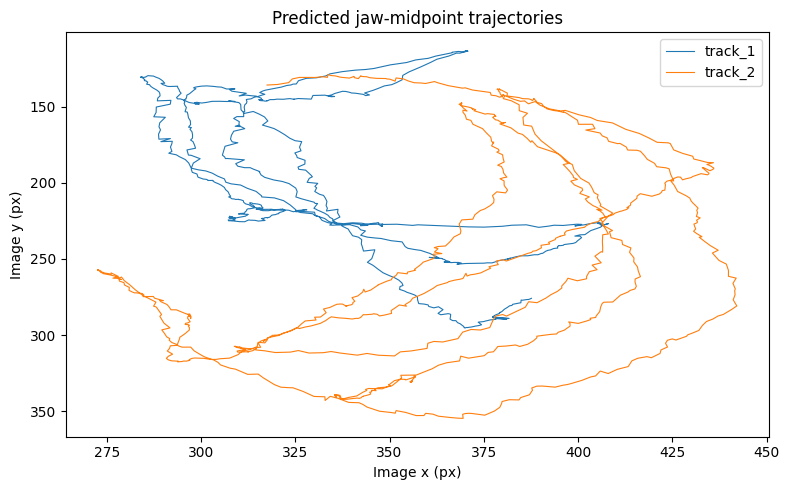

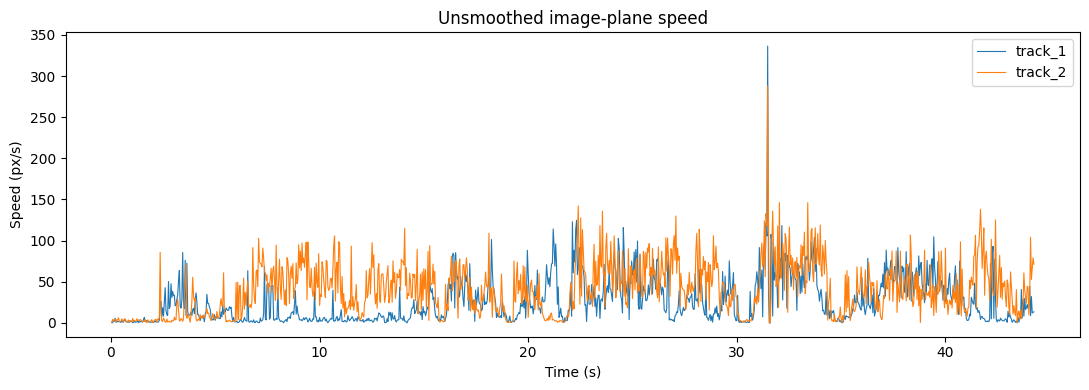

In [7]:
fig, ax = plt.subplots(figsize=(8,5))
for tid, g in kin.groupby('track_id'):
    ax.plot(g['mid_x'], g['mid_y'], linewidth=0.8, label=tid)
ax.set_xlabel('Image x (px)'); ax.set_ylabel('Image y (px)')
ax.invert_yaxis(); ax.set_title('Predicted jaw-midpoint trajectories'); ax.legend()
plt.tight_layout(); plt.savefig(OUTPUT/'trajectories.png', dpi=150); plt.show()

fig, ax = plt.subplots(figsize=(11,4))
for tid, g in kin.groupby('track_id'):
    ax.plot(g['time_s'], g['speed_px_s'], linewidth=0.8, label=tid)
ax.set_xlabel('Time (s)'); ax.set_ylabel('Speed (px/s)')
ax.set_title('Unsmoothed image-plane speed'); ax.legend()
plt.tight_layout(); plt.savefig(OUTPUT/'speed_raw.png', dpi=150); plt.show()

In [13]:
# Inspect the speed spike around 32 seconds
window = kin[
    kin["time_s"].between(31.4, 31.8)
].copy()

print(window.to_string(index=False))

 frame_id           filename  time_s track_id  matched  detection_id  confidence         x1         y1         x2         y2     left_x     left_y  left_conf    right_x    right_y  right_conf      mid_x      mid_y  prev_frame_id  prev_time_s  prev_mid_x  prev_mid_y  dt_s      dx_px     dy_px     vx_px_s    vy_px_s  speed_px_s  direction_deg_image
      786 img_000786_raw.png   31.40  track_1     True             0    0.803234 353.862122 205.129440 393.587219 251.365463 372.632172 225.018814   0.998485 377.562256 233.166336    0.995193 375.097214 229.092575          785.0        31.36  379.921982  228.533417  0.04  -4.824768  0.559158 -120.619202  13.978958  121.426534           173.389294
      787 img_000787_raw.png   31.44  track_1     True             0    0.805805 348.339569 204.779816 391.502991 251.795807 369.004608 224.499130   0.998402 372.744873 233.359467    0.992932 370.874741 228.929298          786.0        31.40  375.097214  229.092575  0.04  -4.222473 -0.163277 -105.5618

## 8. Inspect sample overlays
Show detected jaw tips and track IDs on selected frames. Inspect additional frames near speed spikes, occlusions, or suspected identity switches.

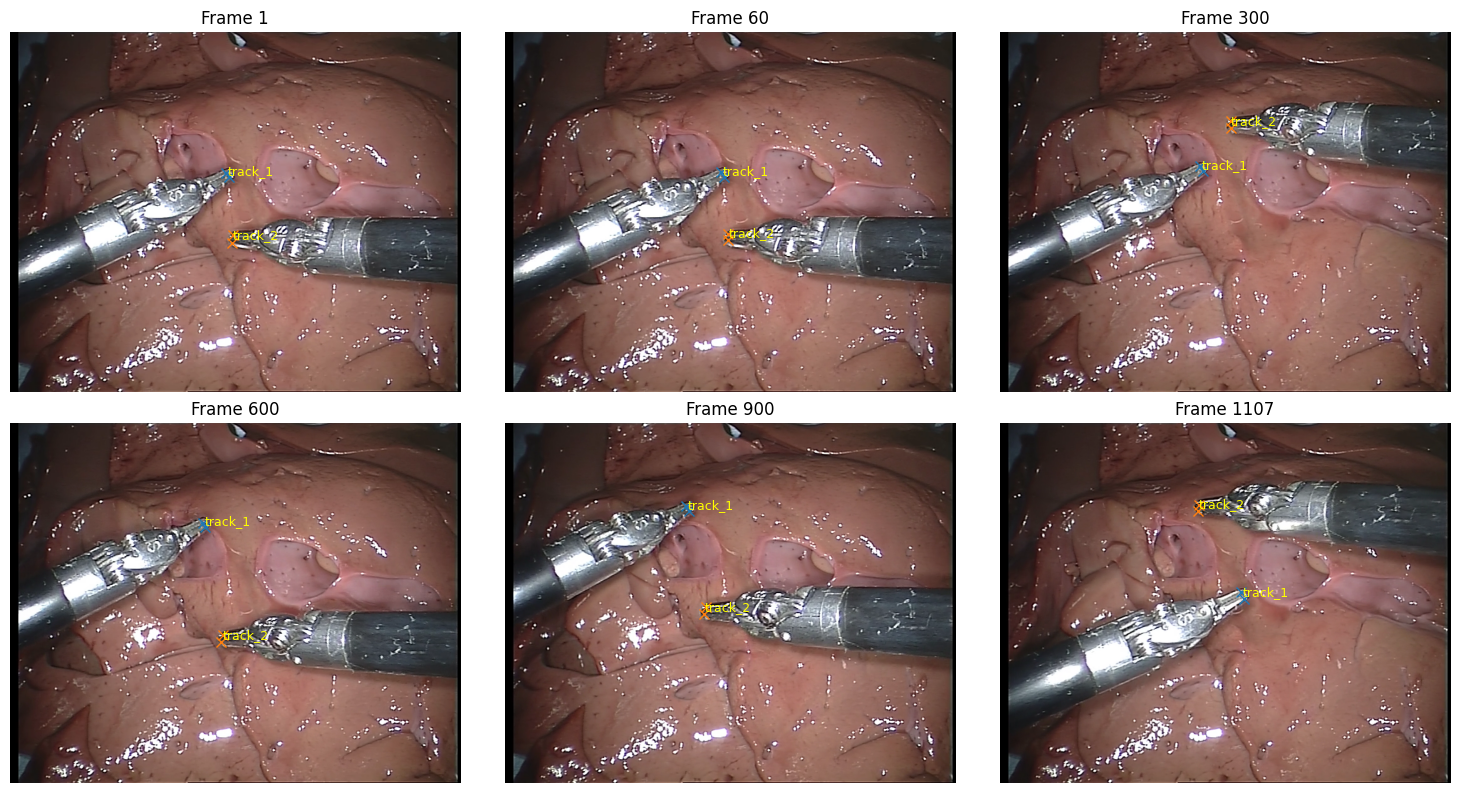

In [8]:
sample_ids = [1, 60, 300, 600, 900, int(timeline.frame_id.iloc[-1])]
fig, axes = plt.subplots(2, 3, figsize=(15,8))
for ax, fid in zip(axes.flat, sample_ids):
    row = timeline.loc[timeline.frame_id == fid]
    if row.empty: ax.axis('off'); continue
    img = cv2.imread(str(FRAMES / row.iloc[0]['filename']))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    ax.imshow(img)
    for _, d in tracked[(tracked.frame_id == fid) & tracked.matched].iterrows():
        ax.plot([d.left_x, d.right_x], [d.left_y, d.right_y], 'x', markersize=7)
        ax.text((d.left_x+d.right_x)/2, (d.left_y+d.right_y)/2,
                d.track_id, color='yellow', fontsize=9)
    ax.set_title(f'Frame {fid}'); ax.axis('off')
plt.tight_layout(); plt.savefig(OUTPUT/'sample_overlays.png', dpi=150); plt.show()

## 9. Summary and next checks for methodology

- `raw_detections.csv`: all framewise predictions (no identity tracking).
- `tracked_keypoints.csv`: two rows per frame, with missing detections explicitly marked.
- `kinematics_raw.csv`: unsmoothed jaw-midpoint motion estimates, NaN across gaps.
- `trajectories.png`, `speed_raw.png`, `sample_overlays.png`: diagnostic figures.

**Before interpreting velocities:** inspect identity swaps, large speed spikes, and keypoint errors on frames with existing annotations. The original left/right robotic pose TXT files are deliberately not used to assign track IDs; their frame alignment and coordinate definitions require verification first. For a stronger study, assess tracking consistency and optionally compare with pose-derived motion after establishing coordinate conventions. Do not treat unannotated frames as a held-out accuracy test.

Robotic left center ranges:
     center_x  center_y
min        66       232
max       190       406

Robotic right center ranges:
     center_x  center_y
min       466       120
max       639       368

YOLO midpoint ranges:
               mid_x                   mid_y            
                 min         max         min         max
track_id                                                
track_1   283.951019  408.101837  113.183479  295.373306
track_2   272.585449  442.093567  128.880104  354.732498


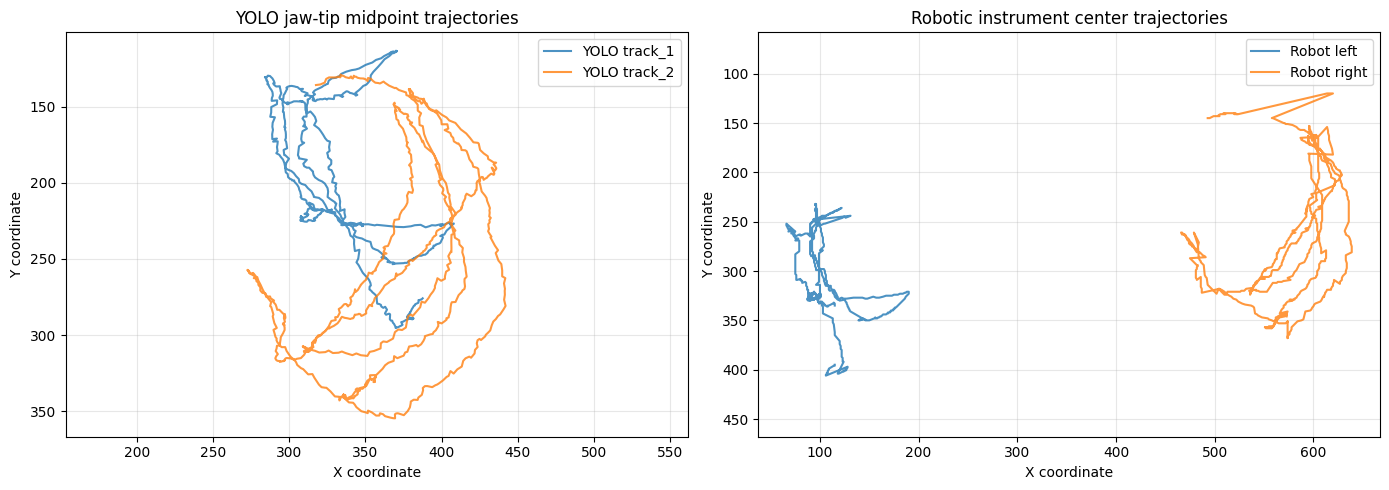

In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Use the tracking output from notebook 03
# If 'tracked' is not currently defined, load the saved CSV.
if "tracked" not in globals():
    tracked = pd.read_csv(
        ROOT / "runs" / "endovis_tracking"
        / "dataset1_baseline" / "tracked_keypoints.csv"
    )

# Compute jaw-tip midpoint coordinates if missing
tracked = tracked.copy()

tracked["mid_x"] = (
    tracked["left_x"] + tracked["right_x"]
) / 2

tracked["mid_y"] = (
    tracked["left_y"] + tracked["right_y"]
) / 2

# Keep matched detections only
yolo = tracked[tracked["matched"] == True].copy()

# Check the instrument center coordinate ranges
print("Robotic left center ranges:")
print(left_pose[["center_x", "center_y"]].agg(["min", "max"]))

print("\nRobotic right center ranges:")
print(right_pose[["center_x", "center_y"]].agg(["min", "max"]))

print("\nYOLO midpoint ranges:")
print(
    yolo.groupby("track_id")[["mid_x", "mid_y"]]
    .agg(["min", "max"])
)

# Compare image-plane trajectories
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for track_id, group in yolo.groupby("track_id"):
    axes[0].plot(
        group["mid_x"],
        group["mid_y"],
        label=f"YOLO {track_id}",
        alpha=0.8
    )

axes[0].set_title("YOLO jaw-tip midpoint trajectories")
axes[0].set_xlabel("X coordinate")
axes[0].set_ylabel("Y coordinate")
axes[0].invert_yaxis()
axes[0].axis("equal")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(
    left_pose["center_x"],
    left_pose["center_y"],
    label="Robot left",
    alpha=0.8
)

axes[1].plot(
    right_pose["center_x"],
    right_pose["center_y"],
    label="Robot right",
    alpha=0.8
)

axes[1].set_title("Robotic instrument center trajectories")
axes[1].set_xlabel("X coordinate")
axes[1].set_ylabel("Y coordinate")
axes[1].invert_yaxis()
axes[1].axis("equal")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

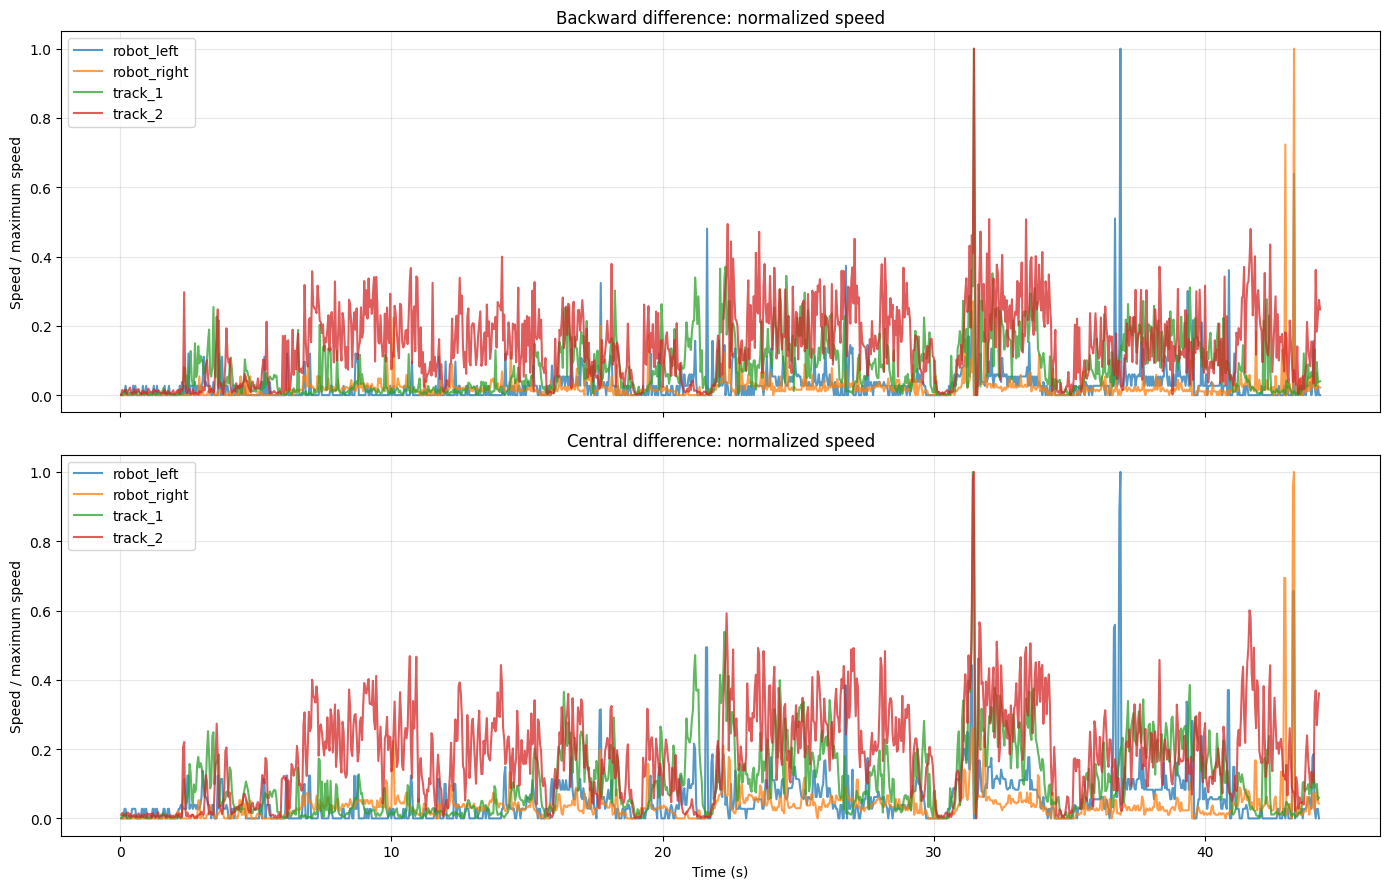

In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Build robotic trajectories
robot = []

for instrument, pose in [
    ("robot_left", left_pose),
    ("robot_right", right_pose)
]:
    temp = pose.copy().reset_index(drop=True)
    temp["frame_id"] = np.arange(1, len(temp) + 1)
    temp["time_s"] = (temp["frame_id"] - 1) / 25
    temp["track_id"] = instrument
    temp["mid_x"] = temp["center_x"]
    temp["mid_y"] = temp["center_y"]

    robot.append(temp)

robot = pd.concat(robot, ignore_index=True)

# Combine with YOLO trajectories
yolo_motion = yolo[
    ["frame_id", "time_s", "track_id", "mid_x", "mid_y"]
].copy()

all_motion = pd.concat([
    yolo_motion,
    robot[["frame_id", "time_s", "track_id", "mid_x", "mid_y"]]
], ignore_index=True)

all_motion = all_motion.sort_values(
    ["track_id", "frame_id"]
).copy()

# Compute velocities
g = all_motion.groupby("track_id")

dt_backward = all_motion["time_s"] - g["time_s"].shift(1)
dt_central = g["time_s"].shift(-1) - g["time_s"].shift(1)

for axis in ["x", "y"]:
    p = all_motion[f"mid_{axis}"]

    all_motion[f"v{axis}_backward"] = (
        p - g[f"mid_{axis}"].shift(1)
    ) / dt_backward

    all_motion[f"v{axis}_central"] = (
        g[f"mid_{axis}"].shift(-1)
        - g[f"mid_{axis}"].shift(1)
    ) / dt_central

for method in ["backward", "central"]:
    all_motion[f"speed_{method}"] = np.hypot(
        all_motion[f"vx_{method}"],
        all_motion[f"vy_{method}"]
    )

# Plot normalized speed profiles
fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True)

for ax, method in zip(axes, ["backward", "central"]):
    for name, group in all_motion.groupby("track_id"):
        speed = group[f"speed_{method}"]

        max_speed = speed.max()
        normalized = speed / max_speed if max_speed > 0 else speed

        ax.plot(
            group["time_s"],
            normalized,
            label=name,
            alpha=0.75
        )

    ax.set_title(f"{method.capitalize()} difference: normalized speed")
    ax.set_ylabel("Speed / maximum speed")
    ax.grid(alpha=0.3)
    ax.legend()

axes[-1].set_xlabel("Time (s)")
plt.tight_layout()
plt.show()

In [23]:
from scipy.stats import pearsonr
import pandas as pd
import numpy as np

results = []

for method in ["backward", "central"]:
    column = f"speed_{method}"

    # One row per frame, one column per instrument
    speed_table = all_motion.pivot_table(
        index="frame_id",
        columns="track_id",
        values=column
    )

    for track in ["track_1", "track_2"]:
        for robot_name in ["robot_left", "robot_right"]:

            pair = speed_table[
                [track, robot_name]
            ].dropna()

            if len(pair) < 3:
                continue

            correlation, p_value = pearsonr(
                pair[track],
                pair[robot_name]
            )

            results.append({
                "method": method,
                "YOLO_track": track,
                "robot_instrument": robot_name,
                "correlation": correlation,
                "p_value": p_value,
                "n_frames": len(pair)
            })

correlation_results = pd.DataFrame(results)

display(
    correlation_results.sort_values(
        ["method", "YOLO_track", "correlation"],
        ascending=[True, True, False]
    )
)

,method,YOLO_track,robot_instrument,correlation,p_value,n_frames
0,backward,track_1,robot_left,0.223318,5.757227e-14,1106
1,backward,track_1,robot_right,0.073044,1.511112e-02,1106
3,backward,track_2,robot_right,0.156531,1.676023e-07,1106
2,backward,track_2,robot_left,0.061298,4.153283e-02,1106
4,central,track_1,robot_left,0.337396,8.004988e-31,1105
5,central,track_1,robot_right,0.115043,1.267975e-04,1105
7,central,track_2,robot_right,0.224116,4.786363e-14,1105
6,central,track_2,robot_left,0.085520,4.443842e-03,1105


,method,track,robot,lag_frames,lag_seconds,correlation
0,backward,track_1,robot_left,5,0.20,0.298185
1,backward,track_2,robot_right,1,0.04,0.190830
2,central,track_1,robot_left,7,0.28,0.434517
3,central,track_2,robot_right,2,0.08,0.250135


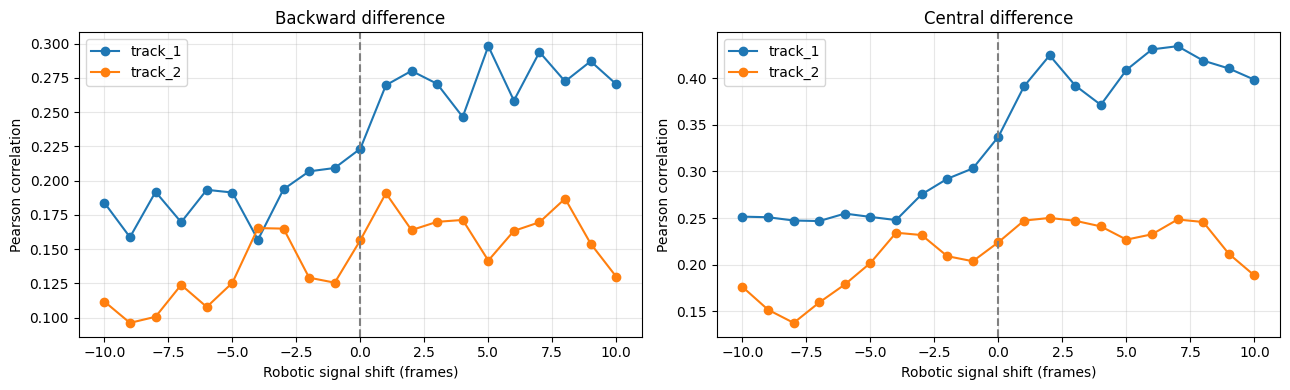

In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

TRACK_MAPPING = {
    "track_1": "robot_left",
    "track_2": "robot_right"
}

MAX_LAG = 10
lag_results = []

speed_table = all_motion.pivot_table(
    index="frame_id",
    columns="track_id",
    values=["speed_backward", "speed_central"]
)

for method in ["backward", "central"]:
    for track, robot_name in TRACK_MAPPING.items():

        yolo_speed = speed_table[
            (f"speed_{method}", track)
        ]

        robot_speed = speed_table[
            (f"speed_{method}", robot_name)
        ]

        for lag in range(-MAX_LAG, MAX_LAG + 1):

            # Positive lag shifts robotic measurements
            # toward later frame IDs.
            shifted_robot = robot_speed.shift(lag)

            pair = pd.concat(
                [yolo_speed, shifted_robot],
                axis=1
            ).dropna()

            if len(pair) < 3:
                continue

            correlation = pair.iloc[:, 0].corr(pair.iloc[:, 1])

            lag_results.append({
                "method": method,
                "track": track,
                "robot": robot_name,
                "lag_frames": lag,
                "lag_seconds": lag / 25,
                "correlation": correlation
            })

lag_df = pd.DataFrame(lag_results)

# Find the strongest positive correlation for each pair
best_lags = (
    lag_df.sort_values("correlation", ascending=False)
    .groupby(["method", "track"], as_index=False)
    .first()
)

display(best_lags)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for ax, method in zip(axes, ["backward", "central"]):
    subset = lag_df[lag_df["method"] == method]

    for track, group in subset.groupby("track"):
        ax.plot(
            group["lag_frames"],
            group["correlation"],
            marker="o",
            label=track
        )

    ax.axvline(0, linestyle="--", color="gray")
    ax.set_title(f"{method.capitalize()} difference")
    ax.set_xlabel("Robotic signal shift (frames)")
    ax.set_ylabel("Pearson correlation")
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

,window_frames,window_seconds,track,robot,correlation,n_samples
0,1,0.04,track_1,robot_left,0.223318,1106
1,1,0.04,track_2,robot_right,0.156531,1106
2,2,0.08,track_1,robot_left,0.337396,1105
3,2,0.08,track_2,robot_right,0.224116,1105
4,3,0.12,track_1,robot_left,0.425122,1104
5,3,0.12,track_2,robot_right,0.278094,1104
6,5,0.20,track_1,robot_left,0.540374,1102
7,5,0.20,track_2,robot_right,0.369887,1102
8,10,0.40,track_1,robot_left,0.749570,1097
9,10,0.40,track_2,robot_right,0.520168,1097


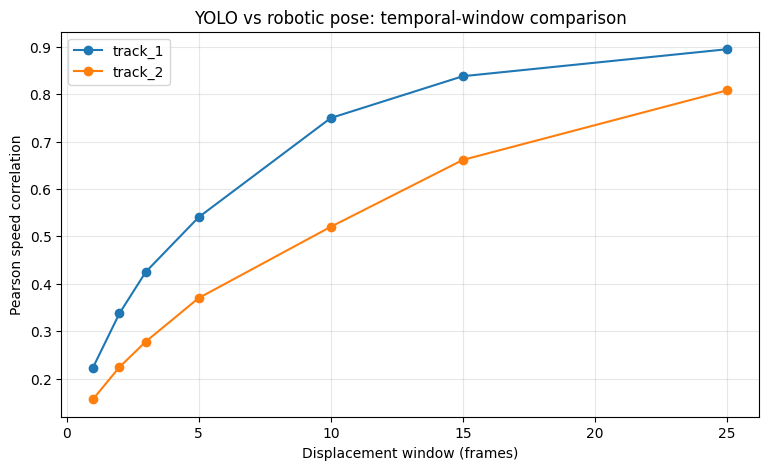

In [25]:
from scipy.stats import pearsonr
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

WINDOWS = [1, 2, 3, 5, 10, 15, 25]

TRACK_MAPPING = {
    "track_1": "robot_left",
    "track_2": "robot_right"
}

window_results = []

for window in WINDOWS:

    motion = all_motion.sort_values(
        ["track_id", "frame_id"]
    ).copy()

    g = motion.groupby("track_id")

    # Displacement over a fixed number of frames
    dx = g["mid_x"].shift(-window) - motion["mid_x"]
    dy = g["mid_y"].shift(-window) - motion["mid_y"]

    dt = g["time_s"].shift(-window) - motion["time_s"]

    # Ensure the shifted sample is exactly 'window' frames away
    next_frame = g["frame_id"].shift(-window)
    valid = (
        (next_frame - motion["frame_id"] == window) &
        (dt > 0)
    )

    motion["window_speed"] = np.where(
        valid,
        np.hypot(dx, dy) / dt,
        np.nan
    )

    table = motion.pivot_table(
        index="frame_id",
        columns="track_id",
        values="window_speed"
    )

    for track, robot_name in TRACK_MAPPING.items():

        pair = table[[track, robot_name]].dropna()

        correlation = pair[track].corr(pair[robot_name])

        window_results.append({
            "window_frames": window,
            "window_seconds": window / 25,
            "track": track,
            "robot": robot_name,
            "correlation": correlation,
            "n_samples": len(pair)
        })

window_results = pd.DataFrame(window_results)

display(window_results)

plt.figure(figsize=(9, 5))

for track, group in window_results.groupby("track"):
    plt.plot(
        group["window_frames"],
        group["correlation"],
        marker="o",
        label=track
    )

plt.xlabel("Displacement window (frames)")
plt.ylabel("Pearson speed correlation")
plt.title("YOLO vs robotic pose: temporal-window comparison")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

In [26]:
WINDOWS = [1, 3, 5, 10, 15, 25]
direction_results = []

for window in WINDOWS:
    motion = all_motion.sort_values(
        ["track_id", "frame_id"]
    ).copy()

    g = motion.groupby("track_id")

    next_frame = g["frame_id"].shift(-window)
    valid = next_frame - motion["frame_id"] == window

    motion["dx"] = (
        g["mid_x"].shift(-window) - motion["mid_x"]
    ).where(valid)

    motion["dy"] = (
        g["mid_y"].shift(-window) - motion["mid_y"]
    ).where(valid)

    dx_table = motion.pivot_table(
        index="frame_id", columns="track_id", values="dx"
    )
    dy_table = motion.pivot_table(
        index="frame_id", columns="track_id", values="dy"
    )

    for track, robot_name in TRACK_MAPPING.items():
        pair = pd.DataFrame({
            "yx": dx_table[track],
            "yy": dy_table[track],
            "rx": dx_table[robot_name],
            "ry": dy_table[robot_name]
        }).dropna()

        y_mag = np.hypot(pair["yx"], pair["yy"])
        r_mag = np.hypot(pair["rx"], pair["ry"])

        # Exclude nearly stationary intervals
        moving = (y_mag > 2) & (r_mag > 2)

        p = pair.loc[moving]
        ym = y_mag.loc[moving]
        rm = r_mag.loc[moving]

        cosine = (
            p["yx"] * p["rx"] + p["yy"] * p["ry"]
        ) / (ym * rm)

        direction_results.append({
            "window_frames": window,
            "track": track,
            "mean_cosine": cosine.mean(),
            "median_cosine": cosine.median(),
            "n_moving": len(cosine)
        })

direction_df = pd.DataFrame(direction_results)
display(direction_df)

,window_frames,track,mean_cosine,median_cosine,n_moving
0,1,track_1,0.622413,0.819524,53
1,1,track_2,0.715409,0.918394,170
2,3,track_1,0.814561,0.930870,377
3,3,track_2,0.821355,0.962577,724
4,5,track_1,0.853817,0.950896,516
5,5,track_2,0.833311,0.970186,813
6,10,track_1,0.864689,0.961602,715
7,10,track_2,0.890580,0.983019,919
8,15,track_1,0.831106,0.965859,814
9,15,track_2,0.913856,0.985629,965
